# PathSnap: Dataset Exploration, Data Cleaning & EDA

**Course:** PES University UE24CS352A Machine Learning: PathSnap map-matching hackathon
**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator-test partition is never read.

This notebook is self-contained. It reads the raw trip files plus the outputs of the cleaning pipeline
(`src/member1_pipeline.py` → `data/observations.parquet`, `data/candidates.parquet`, `data/inventory.csv`)
and the per-trip audit (`src/eda.py` → `results/eda/trip_inventory.csv`). Every figure is also saved to
`results/figures/eda/` for the report.

| Section | Covers (from *Dataset Exploration.pdf* §4 / §8) |
|---|---|
| 1. Inventory | trips per partition, observations per trip, file availability & sizes, dtypes |
| 2. Data cleaning | missing/invalid values, timestamp ordering, integrity, what we flag vs. drop and why |
| 3. Trajectories | trip length, sampling intervals & gaps, GPS coordinate scatter, speed |
| 4. GPS noise vs. reference | how far GPS sits from the reference route; which trips are unreliable |
| 5. Road network | size, connectivity, isolated nodes, components |
| 6. Reference route | structure, continuity, cardinality vs. GPS points |
| 7. Candidates & features | does the 250 m / 30-candidate setting contain the true arc; are the features separable |
| 8. Findings & decisions | data-quality record, assumptions and decisions |

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import LineCollection
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
from src.data_loader import load_trip, list_trips, verify_trip_integrity, resolve_partition_dir

FIG_DIR = os.path.join(ROOT, "results", "figures", "eda")
os.makedirs(FIG_DIR, exist_ok=True)

# Colours: partition identity (fixed order) + one "flagged" colour + neutral context
C = {"train": "#2a78d6", "student_test": "#eb6834"}
FLAG, ROUTE, ROAD, INK = "#e34948", "#1baf7a", "#c9c8c2", "#52514e"
PARTS = ["train", "student_test"]
EARTH_R = 6_371_000.0

sns.set_theme(style="whitegrid", rc={"grid.color": "#ebeae5", "axes.edgecolor": "#bdbcb6",
                                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
                     "lines.linewidth": 2})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")
    plt.show()

def haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_R * np.arcsin(np.sqrt(a))

def local_xy(lon, lat, lon0, lat0):
    # Local equirectangular projection in metres (fine at trip scale, < ~0.1 % error over 50 km).
    return (np.radians(np.asarray(lon) - lon0) * EARTH_R * np.cos(np.radians(lat0)),
            np.radians(np.asarray(lat) - lat0) * EARTH_R)

def legend_by_partition(ax, **kw):
    handles = [plt.Line2D([], [], marker="o", ls="", color=C[p], label=p) for p in PARTS]
    ax.legend(handles=handles, **kw)

In [2]:
# Pre-computed artefacts (regenerate with `python -m src.eda` and `python -m src.member1_pipeline --output data`)
inv  = pd.read_csv(f"{ROOT}/results/eda/trip_inventory.csv", dtype={"trip_id": str})       # per-trip audit
dq   = pd.read_csv(f"{ROOT}/results/data_quality_report.csv", dtype={"trip_id": str})      # per-trip quality checks
pinv = pd.read_csv(f"{ROOT}/data/inventory.csv", dtype={"trip_id": str})                    # cleaning-pipeline inventory
obs  = pd.read_parquet(f"{ROOT}/data/observations.parquet")                                 # one row per GPS point
obs = obs.sort_values(["split", "trip_id", "obs_idx"]).reset_index(drop=True)

# Per-observation motion (from raw coordinates, geodesic distance in metres)
g = obs.groupby("trip_id", sort=False)
obs["dt_s"]   = obs["t"] - g["t"].shift()
obs["step_m"] = haversine_m(g["longitude"].shift(), g["latitude"].shift(), obs["longitude"], obs["latitude"])
obs["speed_mps"] = np.where(obs["dt_s"] > 0, obs["step_m"] / obs["dt_s"], np.nan)

print(f"trips: {inv.groupby('partition').size().to_dict()}   observations: {len(obs):,}")

trips: {'student_test': 10, 'train': 80}   observations: 227,577


## 1. Dataset inventory

Each trip folder holds four headerless, whitespace-separated files. We parse them with **explicit column names and dtypes**
(`src/data_loader.py`), so a malformed row fails loudly instead of being silently coerced.

| File | Columns (dtype) | Index meaning |
|---|---|---|
| `.track` | longitude (float64), latitude (float64), timestamp (float64, s) | row = observation index |
| `.nodes` | longitude (float64), latitude (float64) | row = `node_id` (0-based) |
| `.arcs` | from_node_id (int64), to_node_id (int64) | row = `arc_id` (0-based), directed |
| `.route` | arc_id (int64) | chronological reference arc sequence |

In [3]:
sample = load_trip("00000001", "train", base_dir=ROOT)
display(Markdown("**dtypes as parsed (trip 00000001)**"))
display(pd.DataFrame({name: df.dtypes.astype(str) for name, df in
                      [("track", sample.track), ("nodes", sample.nodes), ("arcs", sample.arcs), ("route", sample.route)]}).T.fillna(""))

display(Markdown("**File availability, row counts and NaN cells per partition**"))
display(pd.read_csv(f"{ROOT}/results/eda/missing_values.csv"))

size_cols = ["size_kb_track", "size_kb_nodes", "size_kb_arcs", "size_kb_route"]
display(Markdown("**File size per trip (KB)**"))
display(inv.groupby("partition")[size_cols].agg(["min", "median", "max"]).T.round(1))

display(Markdown("**Partition summary**"))
display(pd.read_csv(f"{ROOT}/results/eda/partition_summary.csv").set_index("partition").T)

**dtypes as parsed (trip 00000001)**

,arc_id,from_node_id,latitude,longitude,timestamp,to_node_id
track,,,float64,float64,float64,
nodes,,,float64,float64,,
arcs,,int64,,,,int64
route,int64,,,,,


**File availability, row counts and NaN cells per partition**

,partition,file,trips_with_file,trips_missing_file,total_rows,nan_cells
0,train,track,80,0,208417,0
1,train,nodes,80,0,1933485,0
2,train,arcs,80,0,3876904,0
3,train,route,80,0,31336,0
4,student_test,track,10,0,19160,0
5,student_test,nodes,10,0,90689,0
6,student_test,arcs,10,0,185041,0
7,student_test,route,10,0,3477,0


**File size per trip (KB)**

partition             student_test   train
size_kb_track min              8.1    11.3
              median          45.0    48.2
              max            130.4   611.7
size_kb_nodes min             36.3     5.8
              median         135.2   200.3
              max            546.2  3027.4
size_kb_arcs  min             33.7     5.2
              median         137.2   205.5
              max            664.3  4066.8
size_kb_route min              0.6     0.3
              median           1.4     1.7
              max              8.7    14.0

**Partition summary**

partition,student_test,train
trips,10.000000,80.000000
total_points,19160.000000,208417.000000
points_median,1420.000000,1529.000000
points_min,262.000000,361.000000
points_max,3958.000000,19313.000000
duration_median_s,1809.500000,1710.001500
track_km_median,20.935588,24.065686
share_dt_1s_mean,0.981990,0.938296
trips_with_gap_gt30s,2.000000,28.000000
arcs_median,13145.000000,19526.500000


**Takeaways.** All 90 trips have all four files, with zero NaN cells. The road-network files dominate disk size
(`.arcs` up to ~4 MB per trip) while tracks are small, which already says that **candidate search must use a spatial index**
and not a scan over all arcs.

## 2. Data cleaning: what we check, what we fix, what we only flag

**Policy: raw files are never modified, and GPS points are flagged rather than deleted.** The reasons:

* At evaluation the API must return a route for the *whole* trip. If a cleaning step deleted points at inference,
  the decoded route would have holes exactly where the data is hardest.
* Noise is the thing we are modelling. The HMM/Viterbi decoder absorbs a noisy point through its emission probability,
  and a gap through the transition model (which sees `dt_s`). Deleting noise would hide the problem from the model rather than solve it.
* Every cleaning step must run **identically at training and inference** and must never read the `.route` file.
  `src/member1_io.load_trip` doesn't parse `.route` unless `load_reference=True`, and a unit test enforces this.

The cleaning pipeline (`src/network.py`, `src/candidates.py`, `src/features.py`, `src/labels.py`) does the following:

| Step | Where | What happens |
|---|---|---|
| Typed parsing | `data_loader.py` | explicit names and dtypes; bad rows raise |
| Structural integrity | `verify_trip_integrity` | coordinates in range; arcs reference existing nodes; route references existing arcs; timestamps non-decreasing; route arc-to-arc continuity |
| Coordinate validity | `candidates.py` | `valid_coordinate` = finite, in range, and projectable; invalid points get **no candidates** but keep their row |
| Projection to metres | `network.py` | per-trip **UTM zone** chosen from the network median (falls back to azimuthal-equidistant near the poles). Degrees are never used as distances. |
| Road-network repair | `network.py` | arcs with out-of-range node ids or **zero length** are dropped. Parallel duplicate arcs are collapsed to the shortest for the routing graph. |
| Time validity | `features.py` | `time_valid` = `dt > 0`. Speed and `dt_s` are NaN otherwise (no divide-by-zero or inf). |
| Motion validity | `features.py` | `motion_valid` = moved > 0.5 m. Heading is undefined (NaN) for a stationary point, not a fake 0°. |
| Label reliability | `labels.py` | each point is aligned to the reference route monotonically. If the aligned arc is > 50 m away the point is flagged `unreliable`. |

The table below gives the counts across all 90 trips.

In [4]:
route_breaks = ((100 - inv["route_continuity_pct"]) / 100 * (inv["n_route_arcs"] - 1)).round().astype(int)
known = obs["reference_available"]
checks = pd.DataFrame([
    ("Missing longitude/latitude",             dq.missing_coords.sum(),            "none needed"),
    ("Missing timestamps",                     dq.missing_timestamps.sum(),        "none needed"),
    ("Coordinates outside valid lon/lat range", dq.invalid_coords.sum(),           "would be flagged `valid_coordinate=False`"),
    ("Arc -> node id out of range",            dq.invalid_node_references.sum(),   "arc would be dropped from network"),
    ("Route -> arc id out of range",           dq.invalid_arc_references.sum(),    "pipeline raises (needs manual policy)"),
    ("Non-increasing timestamps (dt <= 0)",    dq.non_monotonic_timestamps.sum() + dq.duplicate_timestamps.sum(), "`time_valid=0`, speed=NaN"),
    ("Repeated identical coordinates",         dq.duplicate_coords.sum(),          "kept; `motion_valid=0`, heading=NaN"),
    ("Sampling gaps > 5 s",                    inv.n_gaps_gt5s.sum(),              "kept; `dt_s` feature + HMM transition"),
    ("Sampling gaps > 30 s",                   pinv.gaps_over_30s.sum(),           "kept; HMM transition widens search"),
    ("Implied speed > 70 m/s (GPS jump)",      inv.n_speed_jumps.sum(),            "kept; emission prob. absorbs it"),
    ("Zero-length / invalid arcs",             (pinv.raw_arcs - pinv.usable_arcs).sum(), "**dropped** from network"),
    ("Isolated road nodes",                    pinv.isolated_nodes.sum(),          "none needed"),
    ("Reference route arc-to-arc breaks",      route_breaks.sum(),                 "documented label limitation"),
    ("GPS points with no candidate in 250 m",  pinv.no_candidates.sum(),           "none needed"),
    ("GPS points > 50 m from reference route", int((known & obs.unreliable).sum()), "flagged `unreliable` (see Section 4)"),
    ("GPS points whose true arc is not a candidate", int((known & ~obs.candidate_hit).sum()), "candidate miss (see Section 7)"),
], columns=["Check", "Count (90 trips)", "Action"])
checks["Share"] = ""
n_obs, n_steps = len(obs), len(obs) - obs.trip_id.nunique()
for i, row in checks.iterrows():
    denom = n_steps if any(k in row.Check for k in ["dt", "gaps", "speed", "identical"]) else n_obs if "GPS points" in row.Check else None
    if denom and row["Count (90 trips)"]:
        checks.loc[i, "Share"] = f"{row['Count (90 trips)'] / denom:.2%}"
display(checks.style.hide(axis="index"))

print(f"Distinct UTM zones across trips: {inv.utm_zone.nunique()} (so a single global projection is not an option)")
print(f"Trips with a structural integrity issue: {(inv.integrity_issues.fillna('') != '').sum()}")

Check,Count (90 trips),Action,Share
Missing longitude/latitude,0,none needed,
Missing timestamps,0,none needed,
Coordinates outside valid lon/lat range,0,would be flagged `valid_coordinate=False`,
Arc -> node id out of range,0,arc would be dropped from network,
Route -> arc id out of range,0,pipeline raises (needs manual policy),
Non-increasing timestamps (dt <= 0),0,"`time_valid=0`, speed=NaN",
Repeated identical coordinates,1139,"kept; `motion_valid=0`, heading=NaN",0.50%
Sampling gaps > 5 s,1260,kept; `dt_s` feature + HMM transition,0.55%
Sampling gaps > 30 s,135,kept; HMM transition widens search,0.06%
Implied speed > 70 m/s (GPS jump),148,kept; emission prob. absorbs it,0.07%


Distinct UTM zones across trips: 23 (so a single global projection is not an option)
Trips with a structural integrity issue: 0


**What this tells us.** The files are *structurally* clean: there are no missing values, no out-of-range ids, and no
time reversals. The real problems are *physical*:

1. **Irregular sampling and gaps.** About 3% of steps are not 1 s apart (some trips are much worse), and some gaps last hours or days.
2. **GPS jumps.** Some steps imply speeds above 250 km/h.
3. **About 10% of points sit more than 50 m from the reference route.** Section 4 shows these come mostly from two trips,
   and their labels are untrustworthy.

None of these are fixed by deleting rows. They are handled by features (`dt_s`, `speed_mps`, `motion_valid`), by the
HMM, and by the `unreliable` label flag.

## 3. Trajectories

### 3.1 Trip length and duration

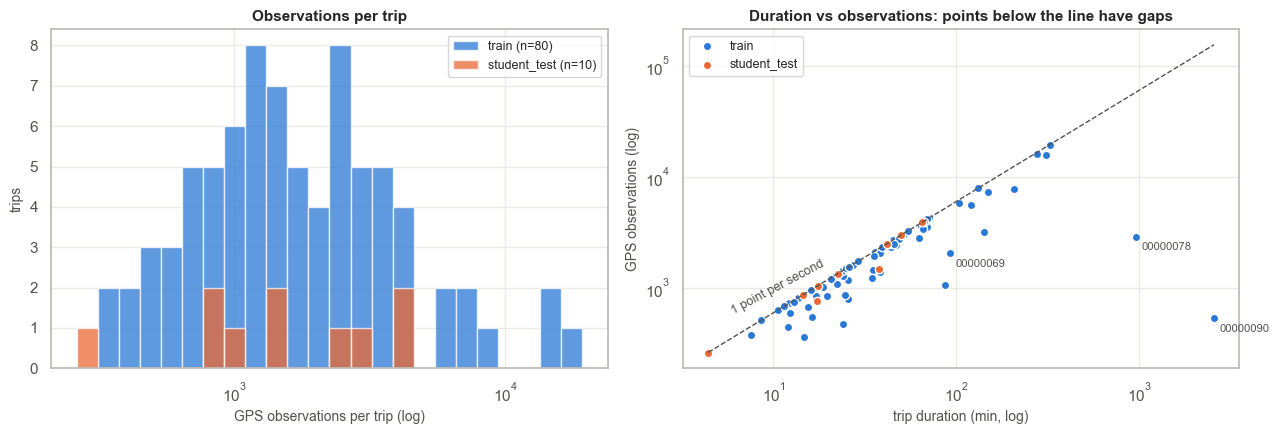

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(np.log10(inv.n_points.min()), np.log10(inv.n_points.max()), 25)
for p in PARTS:
    ax[0].hist(inv.loc[inv.partition == p, "n_points"], bins=bins, color=C[p], alpha=.75,
               label=f"{p} (n={(inv.partition == p).sum()})", edgecolor="white", linewidth=1)
ax[0].set(xscale="log", xlabel="GPS observations per trip (log)", ylabel="trips", title="Observations per trip")
ax[0].legend()

for p in PARTS:
    s = inv[inv.partition == p]
    ax[1].scatter(s.duration_s / 60, s.n_points, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
lim = np.array([inv.duration_s.min() / 60, inv.duration_s.max() / 60])
ax[1].plot(lim, lim * 60, color=INK, lw=1, ls="--")
ax[1].text(lim[0] * 1.3, lim[0] * 60 * 2.2, "1 point per second", color=INK, fontsize=9, rotation=28)
ax[1].set(xscale="log", yscale="log", xlabel="trip duration (min, log)", ylabel="GPS observations (log)",
          title="Duration vs observations: points below the line have gaps")
for r in inv.nlargest(3, "dt_max_s").itertuples():
    ax[1].annotate(r.trip_id, (r.duration_s / 60, r.n_points), fontsize=8, color=INK, xytext=(4, -10), textcoords="offset points")
ax[1].legend()
save(fig, "01_trip_length.png")

The counts are heavily right-skewed: the median is about 1,500 points (about 25 min), but a few trips run past 15,000.
That is why the second panel uses log axes. On the right, a trip sampled perfectly at 1 Hz sits on the dashed line.
Trips far below it (e.g. `00000090`, `00000078`) contain huge recording gaps: their *duration* is days while their point
count is ordinary. The two partitions overlap well, so `student_test` is representative of `train`.

### 3.2 Sampling intervals and gaps

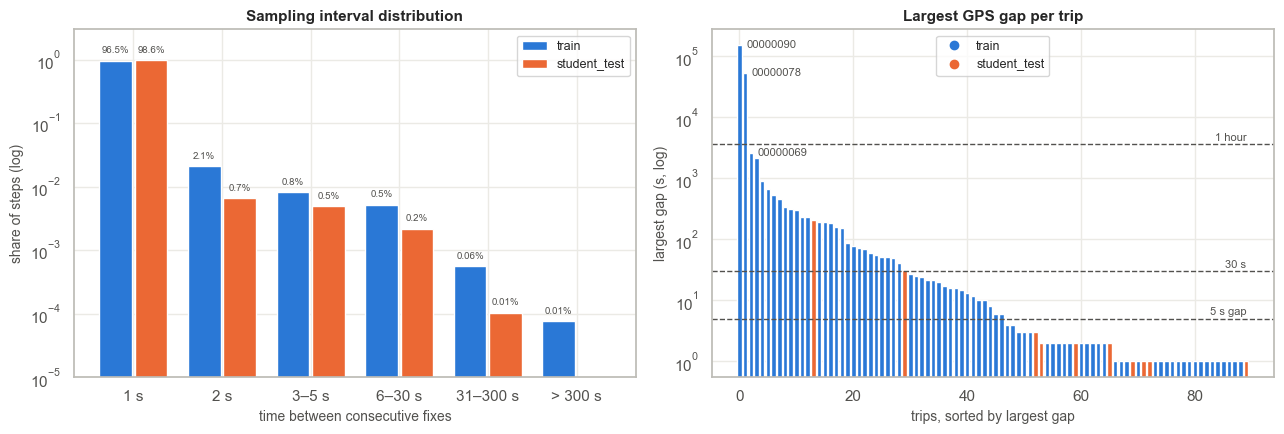

share of exact 1 s steps: 96.68% | steps > 5 s: 1,260 | trips with a gap > 30 s: 30


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dt = obs.dt_s.dropna()
edges  = [0, 1, 2, 5, 30, 300, np.inf]
labels = ["1 s", "2 s", "3–5 s", "6–30 s", "31–300 s", "> 300 s"]
cats = pd.cut(dt, [-np.inf, 1, 2, 5, 30, 300, np.inf], labels=labels)
tab = pd.crosstab(cats, obs.loc[dt.index, "split"]).reindex(columns=PARTS)
x = np.arange(len(labels)); w = .4
for j, p in enumerate(PARTS):
    share = tab[p] / tab[p].sum()
    bars = ax[0].bar(x + (j - .5) * w, share, w * .92, color=C[p], label=p)
    for xi, v in zip(x + (j - .5) * w, share):
        if v > 0:
            ax[0].text(xi, v * 1.3, f"{v:.1%}" if v >= .001 else f"{v:.2%}", ha="center", fontsize=7, color=INK)
ax[0].set(yscale="log", xticks=x, xticklabels=labels, ylim=(1e-5, 3), ylabel="share of steps (log)",
          xlabel="time between consecutive fixes", title="Sampling interval distribution")
ax[0].legend(loc="upper right")

s = inv.sort_values("dt_max_s", ascending=False).reset_index(drop=True)
ax[1].bar(s.index, s.dt_max_s, color=[C[p] for p in s.partition], width=.8)
for y, lab in [(5, "5 s gap"), (30, "30 s"), (3600, "1 hour")]:
    ax[1].axhline(y, color=INK, lw=1, ls="--"); ax[1].text(len(s) - 1, y * 1.15, lab, ha="right", fontsize=8, color=INK)
for r in s.head(3).itertuples():
    ax[1].text(r.Index + 1.2, r.dt_max_s, r.trip_id, fontsize=8, color=INK, va="center")
ax[1].set(yscale="log", xlabel="trips, sorted by largest gap", ylabel="largest gap (s, log)", title="Largest GPS gap per trip")
legend_by_partition(ax[1], loc="upper center")
save(fig, "02_sampling_gaps.png")
print(f"share of exact 1 s steps: {(dt == 1).mean():.2%} | steps > 5 s: {(dt > 5).sum():,} | trips with a gap > 30 s: {(inv.dt_max_s > 30).sum()}")

Nominally the tracks are 1 Hz: about 97% of all steps are exactly 1 s (94% on a per-trip average, because a few trips are much worse). The tail matters, though. Gaps of 6–300 s mean the vehicle can
cross several arcs (or a whole junction) between two fixes, so the decoder **must route through the network** between
points rather than assume consecutive points share or neighbour an arc. The largest gaps (days, in `00000090` and `00000078`)
are separate recording sessions concatenated into one trip. The bar chart uses a log axis. A linear histogram (as in the
old figure) collapses 88 of 90 trips into a single bar and hides all of this.

### 3.3 GPS coordinate distribution: where the trips are, and what the raw points look like

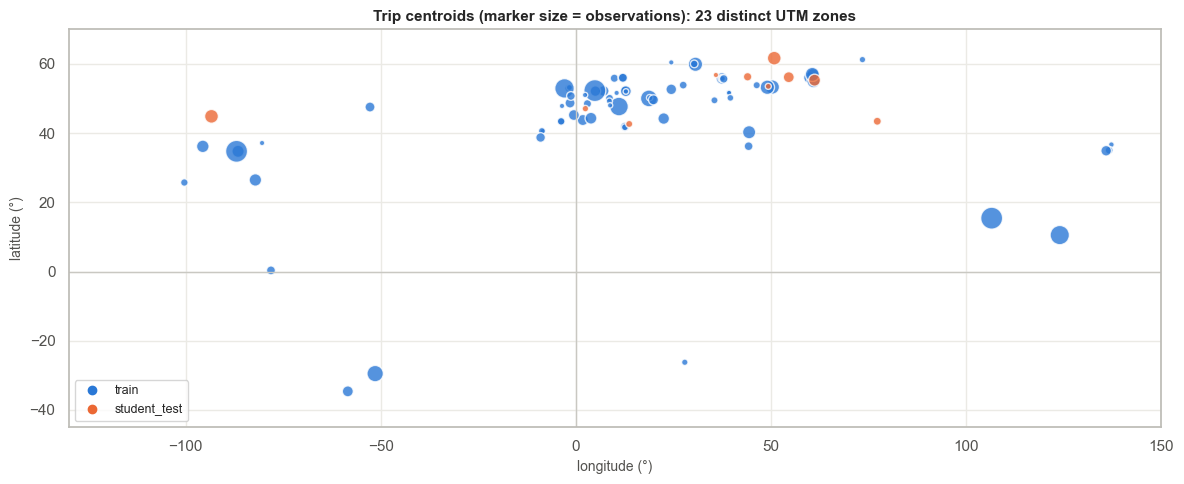

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for p in PARTS:
    s = inv[inv.partition == p]
    ax.scatter(s.center_lon, s.center_lat, s=np.clip(s.n_points / 40, 15, 250), color=C[p], alpha=.8,
               edgecolor="white", linewidth=1, label=p)
ax.set(xlim=(-130, 150), ylim=(-45, 70), xlabel="longitude (°)", ylabel="latitude (°)",
       title=f"Trip centroids (marker size = observations): {inv.utm_zone.nunique()} distinct UTM zones")
ax.axhline(0, color=ROAD, lw=1); ax.axvline(0, color=ROAD, lw=1)
legend_by_partition(ax, loc="lower left")
save(fig, "03_trip_locations.png")

Trips are spread across Europe, Asia, the Americas and Australia (both hemispheres, both signs of longitude).
Two consequences follow. **(a)** Euclidean distance in degrees is meaningless: one degree of longitude is about 111 km at the equator but
about 55 km at 60°N. **(b)** No single projected CRS fits every trip, so the pipeline picks the UTM zone per trip.
All lon/lat values are within valid ranges, and every track lies inside its own road-network bounding box, which confirms
that the column order is **longitude first**.

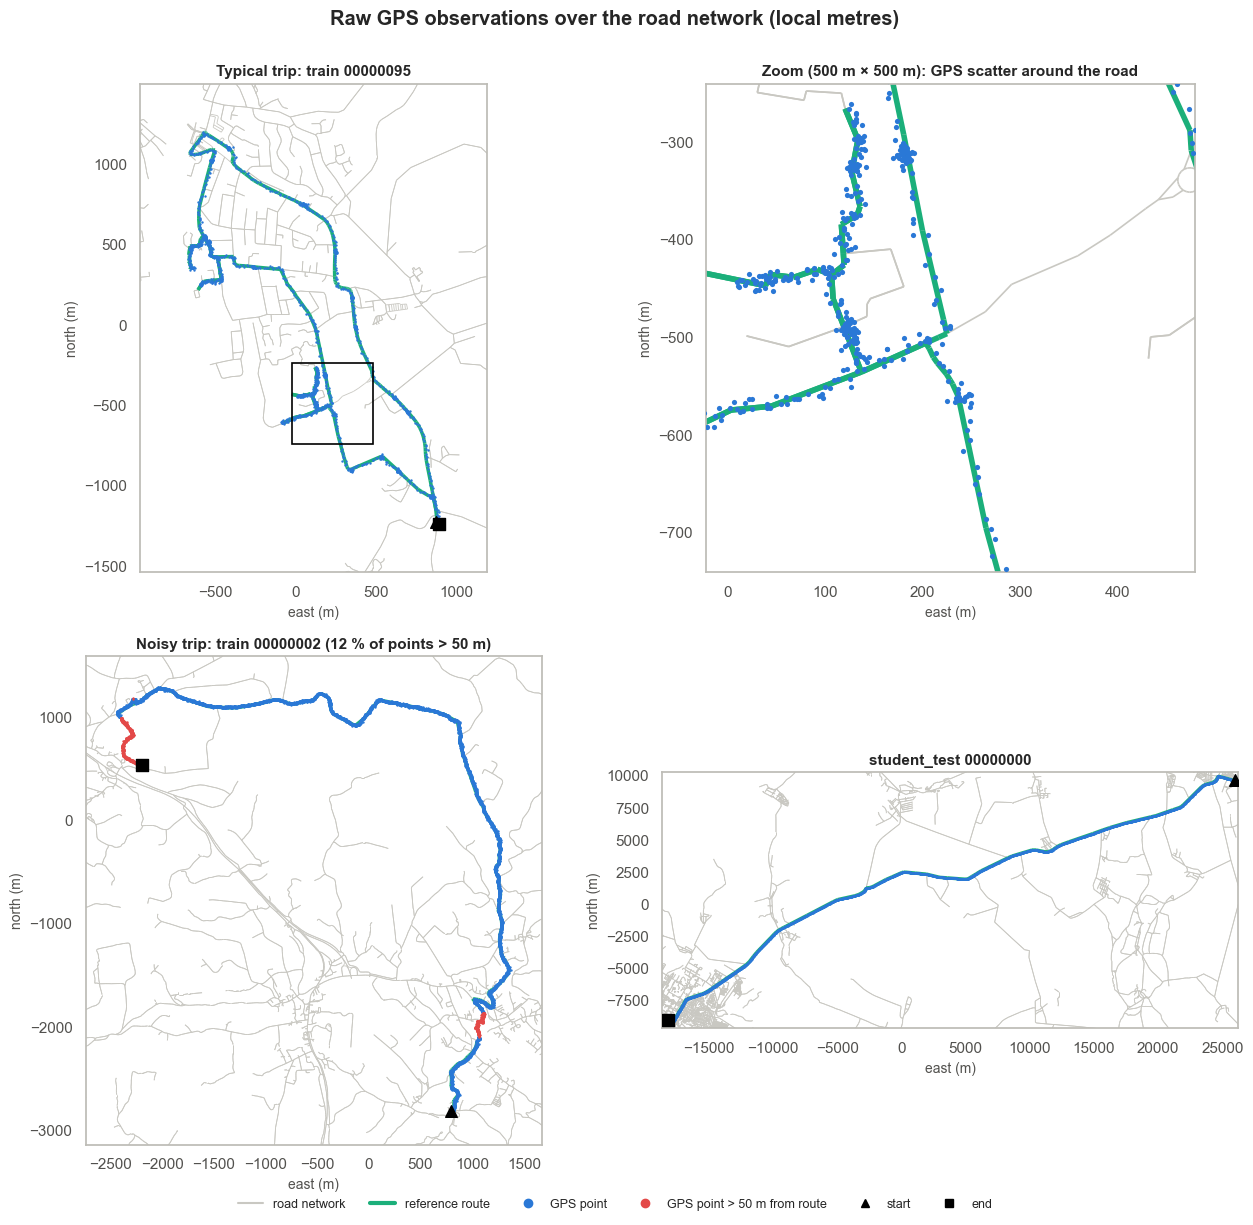

In [8]:
def road_segments(trip, lon0, lat0, bbox_m):
    n = trip.nodes.to_numpy(); a = trip.arcs.to_numpy()
    x, y = local_xy(n[:, 0], n[:, 1], lon0, lat0)
    xmin, xmax, ymin, ymax = bbox_m
    inside = (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax)
    keep = inside[a[:, 0]] | inside[a[:, 1]]
    return np.stack([np.c_[x[a[keep, 0]], y[a[keep, 0]]], np.c_[x[a[keep, 1]], y[a[keep, 1]]]], axis=1), x, y

def draw_trip(ax, trip_id, partition, zoom=None, pad=300, title=None):
    trip = load_trip(trip_id, partition, base_dir=ROOT)
    tr = trip.track
    lon0, lat0 = tr.longitude.mean(), tr.latitude.mean()
    gx, gy = local_xy(tr.longitude, tr.latitude, lon0, lat0)
    bbox = (gx.min() - pad, gx.max() + pad, gy.min() - pad, gy.max() + pad) if zoom is None else zoom
    segs, nx, ny = road_segments(trip, lon0, lat0, bbox)
    ax.add_collection(LineCollection(segs, colors=ROAD, linewidths=.6 if zoom is None else 1.2, zorder=1))
    r = trip.arcs.iloc[trip.route.arc_id.to_numpy()].to_numpy()
    route = np.stack([np.c_[nx[r[:, 0]], ny[r[:, 0]]], np.c_[nx[r[:, 1]], ny[r[:, 1]]]], axis=1)
    ax.add_collection(LineCollection(route, colors=ROUTE, linewidths=2.5 if zoom is None else 4, zorder=2))
    o = obs[obs.trip_id == trip_id]
    far = o.unreliable.to_numpy()
    ax.scatter(gx[~far], gy[~far], s=3 if zoom is None else 14, color=C["train"], zorder=3, linewidths=0)
    ax.scatter(gx[far], gy[far], s=3 if zoom is None else 14, color=FLAG, zorder=4, linewidths=0)
    ax.scatter(gx[0], gy[0], s=70, marker="^", color="black", zorder=5)
    ax.scatter(gx[-1], gy[-1], s=70, marker="s", color="black", zorder=5)
    ax.set(xlim=bbox[:2], ylim=bbox[2:], aspect="equal", xlabel="east (m)", ylabel="north (m)")
    ax.set_title(title or f"{partition} {trip_id} ({len(tr):,} pts)")
    ax.grid(False)
    return gx, gy

key = [plt.Line2D([], [], color=ROAD, lw=1.5, label="road network"),
       plt.Line2D([], [], color=ROUTE, lw=3, label="reference route"),
       plt.Line2D([], [], marker="o", ls="", color=C["train"], label="GPS point"),
       plt.Line2D([], [], marker="o", ls="", color=FLAG, label="GPS point > 50 m from route"),
       plt.Line2D([], [], marker="^", ls="", color="black", label="start"),
       plt.Line2D([], [], marker="s", ls="", color="black", label="end")]

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
gx, gy = draw_trip(axes[0, 0], "00000095", "train", title="Typical trip: train 00000095")
cx, cy = gx[len(gx) // 3], gy[len(gy) // 3]
zoom = (cx - 250, cx + 250, cy - 250, cy + 250)
axes[0, 0].add_patch(plt.Rectangle((zoom[0], zoom[2]), 500, 500, fill=False, ec="black", lw=1.2, zorder=6))
draw_trip(axes[0, 1], "00000095", "train", zoom=zoom, title="Zoom (500 m × 500 m): GPS scatter around the road")
draw_trip(axes[1, 0], "00000002", "train", title="Noisy trip: train 00000002 (12 % of points > 50 m)")
draw_trip(axes[1, 1], "00000000", "student_test", title="student_test 00000000")
fig.legend(handles=key, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(.5, -.01))
fig.suptitle("Raw GPS observations over the road network (local metres)", fontweight="bold", y=1.0)
save(fig, "04_gps_scatter_on_network.png")

These are the scatter plots of the raw GPS points. In the zoomed panel each blue dot is one fix. The dots form a band a few metres wide
around the green reference road, offset to one side and occasionally drifting onto the parallel or crossing roads.
That is the core difficulty: **nearest-road snapping would pick the wrong arc at junctions and on parallel roads**,
which is why we combine per-point classification with an HMM that enforces connectivity. Trip `00000002` shows
red stretches where the GPS runs well off the reference route.

### 3.4 Speed

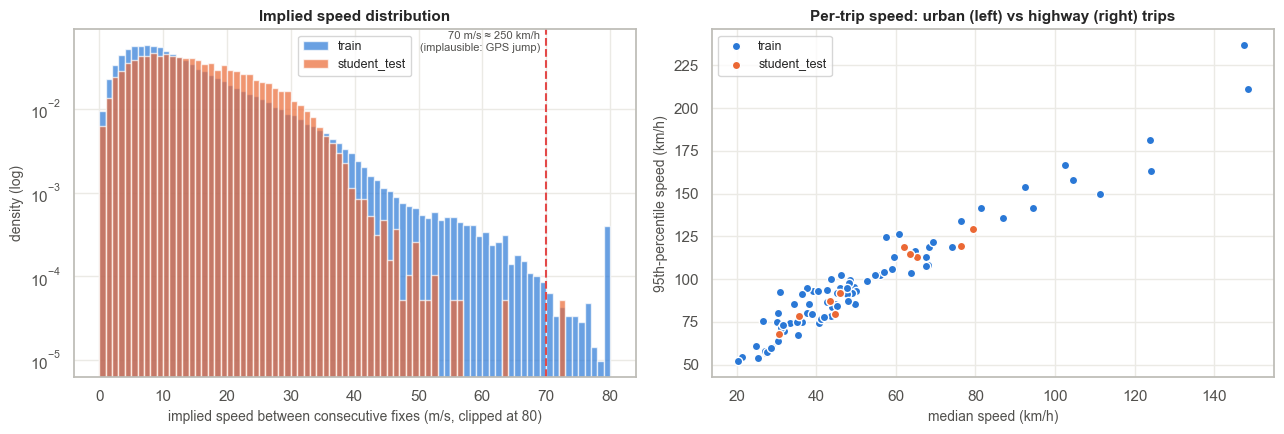

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sp = obs.dropna(subset=["speed_mps"])
bins = np.linspace(0, 80, 81)
for p in PARTS:
    ax[0].hist(np.clip(sp.loc[sp.split == p, "speed_mps"], 0, 80), bins=bins, color=C[p], alpha=.7,
               density=True, label=p, log=True)
ax[0].axvline(70, color=FLAG, lw=1.5, ls="--"); ax[0].text(69, .05, "70 m/s ≈ 250 km/h\n(implausible: GPS jump)", ha="right", fontsize=8, color=INK)
ax[0].set(xlabel="implied speed between consecutive fixes (m/s, clipped at 80)", ylabel="density (log)",
          title="Implied speed distribution")
ax[0].legend()

for p in PARTS:
    s = inv[inv.partition == p]
    ax[1].scatter(s.speed_median_ms * 3.6, s.speed_p95_ms * 3.6, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
ax[1].set(xlabel="median speed (km/h)", ylabel="95th-percentile speed (km/h)",
          title="Per-trip speed: urban (left) vs highway (right) trips")
ax[1].legend()
save(fig, "05_speed.png")

Speeds form a smooth distribution up to about 35 m/s (motorway speeds), with a spike at 0 for stops. The thin tail past 70 m/s
is physically impossible for a car and comes from GPS jumps (multipath) or from timestamp gaps where `dt` is small but the
position has reset. Trips range from slow urban driving (median about 20 km/h) to motorway trips (median up to about 150 km/h).
A fixed "max distance between consecutive matches" would therefore be wrong, and the transition model has to scale with `speed × dt`.

## 4. GPS noise relative to the reference route

The most important question for map matching is **how far is a GPS point from the road it was actually on?**
For every point we measure the distance to the *nearest arc of the reference route* (`nearest_route_distance_m`,
computed in UTM metres). This distribution sets the candidate search radius and the emission-probability scale.

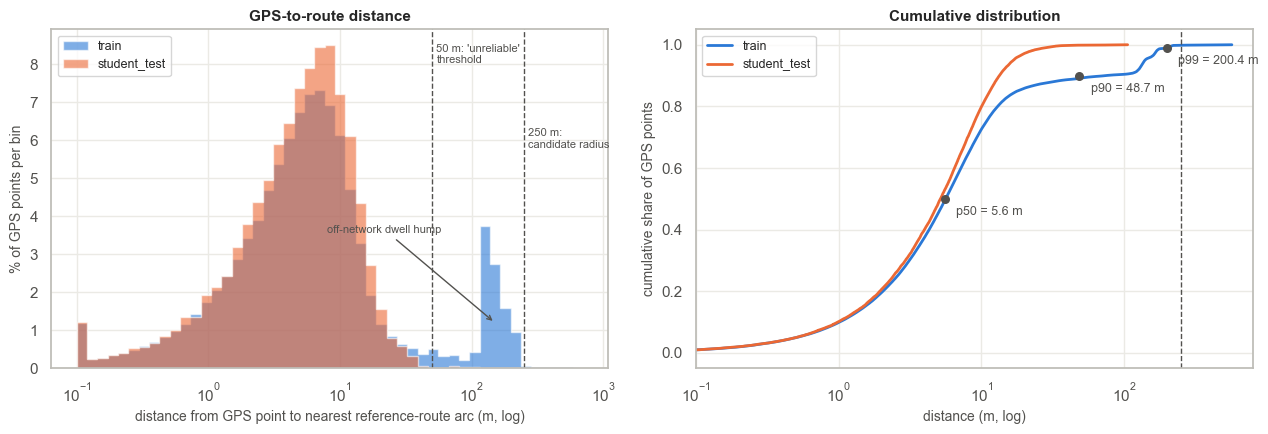

median 5.6 m | within 20 m: 86.8% | > 50 m: 9.9% | > 250 m: 0.15%


In [10]:
d = obs.loc[obs.reference_available, ["split", "trip_id", "nearest_route_distance_m"]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(-1, np.log10(700), 50)
for p in PARTS:
    v = d.loc[d.split == p, "nearest_route_distance_m"].clip(lower=.1)
    ax[0].hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)), color=C[p], alpha=.6, label=p, histtype="stepfilled")
top = ax[0].get_ylim()[1]
for v, lab, y in [(50, "50 m: 'unreliable'\nthreshold", .9), (250, "250 m:\ncandidate radius", .65)]:
    ax[0].axvline(v, color=INK, ls="--", lw=1); ax[0].text(v * 1.08, top * y, lab, fontsize=8, color=INK)
ax[0].annotate("off-network dwell hump", (150, 1.2), xytext=(8, top * .4), fontsize=8, color=INK, arrowprops=dict(arrowstyle="->", color=INK))
ax[0].set(xscale="log", xlabel="distance from GPS point to nearest reference-route arc (m, log)", ylabel="% of GPS points per bin",
          title="GPS-to-route distance")
ax[0].legend(loc="upper left")

for p in PARTS:
    v = np.sort(d.loc[d.split == p, "nearest_route_distance_m"].to_numpy())
    ax[1].plot(v, np.arange(1, len(v) + 1) / len(v), color=C[p], label=p)
allv = d.nearest_route_distance_m
for q in [.5, .9, .99]:
    x = allv.quantile(q)
    ax[1].scatter([x], [q], color=INK, s=30, zorder=3)
    ax[1].annotate(f"p{int(q*100)} = {x:.1f} m", (x, q), xytext=(8, -12), textcoords="offset points", fontsize=9, color=INK)
ax[1].axvline(250, color=INK, ls="--", lw=1)
ax[1].set(xscale="log", xlim=(.1, 800), xlabel="distance (m, log)", ylabel="cumulative share of GPS points",
          title="Cumulative distribution")
ax[1].legend(loc="upper left")
save(fig, "06_gps_noise.png")
print(f"median {allv.median():.1f} m | within 20 m: {(allv <= 20).mean():.1%} | > 50 m: {(allv > 50).mean():.1%} | > 250 m: {(allv > 250).mean():.2%}")

Most points are close: median 5.6 m, and 87% fall within 20 m, which matches normal consumer GPS error. But the
distribution is **bimodal**. A second hump sits around 100–200 m and holds about 10% of `train` points, and `student_test` barely has it.
A Gaussian emission model fitted to *all* points would therefore be badly skewed. The scatter below shows where the hump comes from.

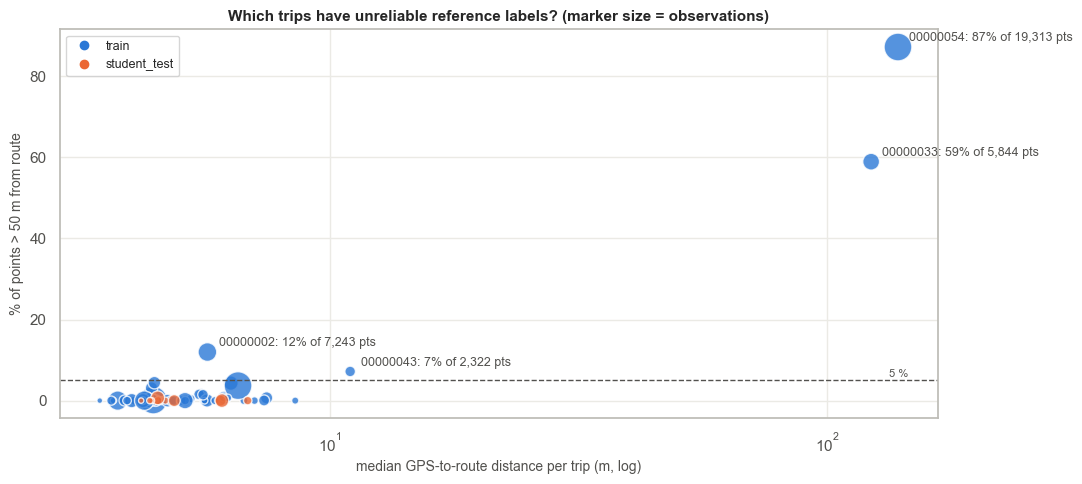

Trips 00000054, 00000033 alone account for 90% of all points > 50 m from the route.


In [11]:
per = (d.groupby(["split", "trip_id"]).nearest_route_distance_m
         .agg(median="median", far_share=lambda x: (x > 50).mean(), n="size").reset_index())
fig, ax = plt.subplots(figsize=(11, 5))
for p in PARTS:
    s = per[per.split == p]
    ax.scatter(s["median"], s.far_share * 100, s=np.clip(s.n / 40, 15, 400), color=C[p], alpha=.8,
               edgecolor="white", linewidth=1, label=p)
for r in per.nlargest(4, "far_share").itertuples():
    ax.annotate(f"{r.trip_id}: {r.far_share:.0%} of {r.n:,} pts", (r[3], r.far_share * 100),
                xytext=(8, 4), textcoords="offset points", fontsize=9, color=INK)
ax.axhline(5, color=INK, ls="--", lw=1); ax.text(ax.get_xlim()[1], 5.8, "5 %", ha="right", fontsize=8, color=INK)
ax.set(xscale="log", xlabel="median GPS-to-route distance per trip (m, log)", ylabel="% of points > 50 m from route",
       title="Which trips have unreliable reference labels? (marker size = observations)")
legend_by_partition(ax, loc="upper left")
save(fig, "07_noise_per_trip.png")

top = per.nlargest(2, "far_share")
share_of_all = (d.nearest_route_distance_m > 50).groupby(d.trip_id).sum().loc[top.trip_id].sum() / (d.nearest_route_distance_m > 50).sum()
print(f"Trips {', '.join(top.trip_id)} alone account for {share_of_all:.0%} of all points > 50 m from the route.")

Almost every trip has under 5% far points. Two `train` trips are extreme outliers: **`00000054` (about 87%)** and **`00000033` (about 59%)**.
Together they account for most of the far points in the whole dataset. The next figure shows what happens in them.

00000054: flagged 17,274/19,313 points; median implied speed of flagged points 7.1 m/s; spatial spread (std) 163 m × 174 m


00000033: flagged 3,449/5,844 points; median implied speed of flagged points 6.6 m/s; spatial spread (std) 83 m × 327 m


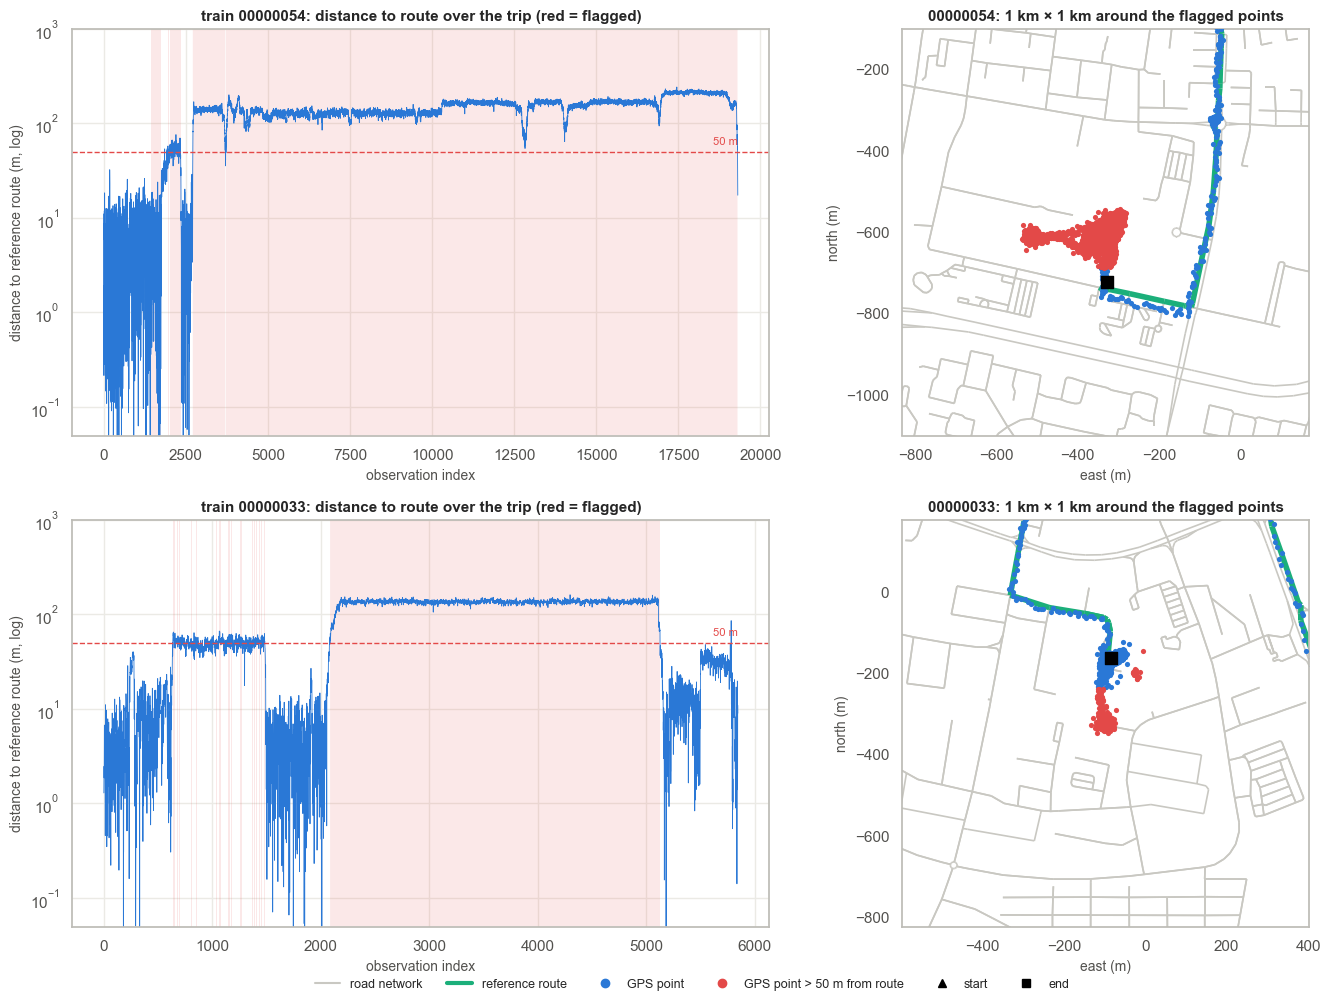

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), gridspec_kw={"width_ratios": [1.3, 1]})
for row, tid in enumerate(["00000054", "00000033"]):
    o = obs[obs.trip_id == tid]
    ax = axes[row, 0]
    ax.plot(o.obs_idx, o.nearest_route_distance_m.clip(lower=.05), color=C["train"], lw=.6)
    ax.fill_between(o.obs_idx, .05, 1000, where=o.unreliable.to_numpy(), color=FLAG, alpha=.12, lw=0)
    ax.axhline(50, color=FLAG, ls="--", lw=1); ax.text(o.obs_idx.max(), 60, "50 m", ha="right", fontsize=8, color=FLAG)
    ax.set(yscale="log", ylim=(.05, 1000), xlabel="observation index", ylabel="distance to reference route (m, log)",
           title=f"train {tid}: distance to route over the trip (red = flagged)")
    tr = load_trip(tid, "train", base_dir=ROOT).track
    lon0, lat0 = tr.longitude.mean(), tr.latitude.mean()
    gx, gy = local_xy(tr.longitude, tr.latitude, lon0, lat0)
    far = o.unreliable.to_numpy()
    cx, cy = np.median(gx[far]), np.median(gy[far])
    draw_trip(axes[row, 1], tid, "train", zoom=(cx - 500, cx + 500, cy - 500, cy + 500),
              title=f"{tid}: 1 km × 1 km around the flagged points")
    print(f"{tid}: flagged {far.sum():,}/{len(far):,} points; median implied speed of flagged points "
          f"{o.loc[o.unreliable, 'speed_mps'].median():.1f} m/s; spatial spread (std) {np.std(gx[far]):.0f} m × {np.std(gy[far]):.0f} m")
fig.legend(handles=key, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(.5, -.01))
save(fig, "08_off_network_dwell.png")

**Diagnosis: off-network dwell.** In `00000054` the vehicle reaches the end of the reference route and then spends about **4.6 hours
inside a roadless block a couple of hundred metres across**: a depot, car park or private yard that is not in the road network.
In `00000033` the same happens mid-trip for about 50 minutes, after which the vehicle returns to the route.
GPS jitter during the dwell produces implied speeds of about 7 m/s, so a **speed threshold does not detect it as stationary**.
The tell is a small spatial area combined with a very long time.

Why it matters:
* The monotone alignment still assigns these points to the nearest route arc (the last one), so they become
  **wrong positive labels**: about 20k of the 23k unreliable training labels.
* The cleaning pipeline already computes the `unreliable` flag, **but no training script filters on it**.

**Decision (recommended):** exclude `unreliable == True` observations from classifier *training* and from the emission-noise
fit. Keep them at inference, where the HMM will snap them to the route end. They are not removed from evaluation.
This affects about 10% of train rows and needs a model re-run to quantify, so it is listed in Section 8 rather than applied silently here.

## 5. Road network: size and connectivity

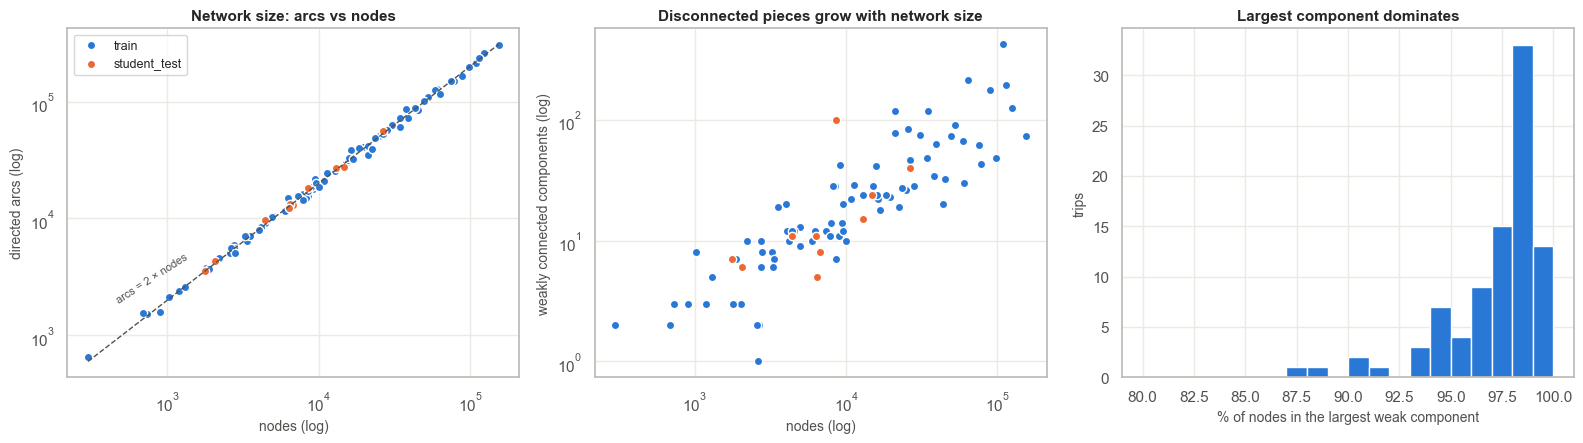

,min,50%,mean,max
n_nodes,299.000,9305.000,22490.822,155003.000
n_arcs,649.000,18761.500,45132.722,307392.000
n_weak_components,1.000,19.000,37.200,421.000
n_strong_components,2.000,107.000,233.467,1942.000
largest_component_share,0.693,0.980,0.968,1.000
isolated_nodes,0.000,0.000,0.000,0.000
self_loops,0.000,0.000,0.267,8.000
duplicate_arcs,0.000,2.500,21.144,322.000
two_way_arc_share,0.351,0.951,0.922,1.000
arc_len_median_m,6.738,25.091,30.468,84.903


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for p in PARTS:
    s = inv[inv.partition == p]
    ax[0].scatter(s.n_nodes, s.n_arcs, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
    ax[1].scatter(s.n_nodes, s.n_weak_components, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
x = np.array([inv.n_nodes.min(), inv.n_nodes.max()])
ax[0].plot(x, 2 * x, color=INK, ls="--", lw=1); ax[0].text(x[0] * 1.5, 2 * x[0] * 3.2, "arcs = 2 × nodes", fontsize=8, color=INK, rotation=33)
ax[0].set(xscale="log", yscale="log", xlabel="nodes (log)", ylabel="directed arcs (log)", title="Network size: arcs vs nodes")
ax[0].legend()
ax[1].set(xscale="log", yscale="log", xlabel="nodes (log)", ylabel="weakly connected components (log)",
          title="Disconnected pieces grow with network size")
ax[2].hist(inv.largest_component_share * 100, bins=np.linspace(80, 100, 21), color=C["train"], edgecolor="white")
ax[2].set(xlabel="% of nodes in the largest weak component", ylabel="trips", title="Largest component dominates")
save(fig, "09_network_connectivity.png")

net = inv[["n_nodes", "n_arcs", "n_weak_components", "n_strong_components", "largest_component_share",
           "isolated_nodes", "self_loops", "duplicate_arcs", "two_way_arc_share", "arc_len_median_m", "arc_len_max_m"]]
display(net.describe().T[["min", "50%", "mean", "max"]].round(3))

* Arcs ≈ 2 × nodes, and the median two-way share is about 95%: most roads are stored as **two directed arcs**, one per direction.
  At a two-way road, the correct arc and its reverse twin are geometrically identical, so the model has to use
  **heading** (`heading_cosine`) to tell them apart.
* Networks range from about 600 to over 300,000 arcs, which is why candidate search uses an STR-tree spatial index.
* Every network has many small disconnected components (dangling clipped edges at the bounding-box border), but the largest component
  usually holds most of the network (median 98% of nodes, worst trip 69%). There are no isolated nodes. The many strong components mean some one-way pieces can be
  entered but not left, so the HMM must treat "no path" transitions as near-zero probability rather than crash.

## 6. Reference route structure

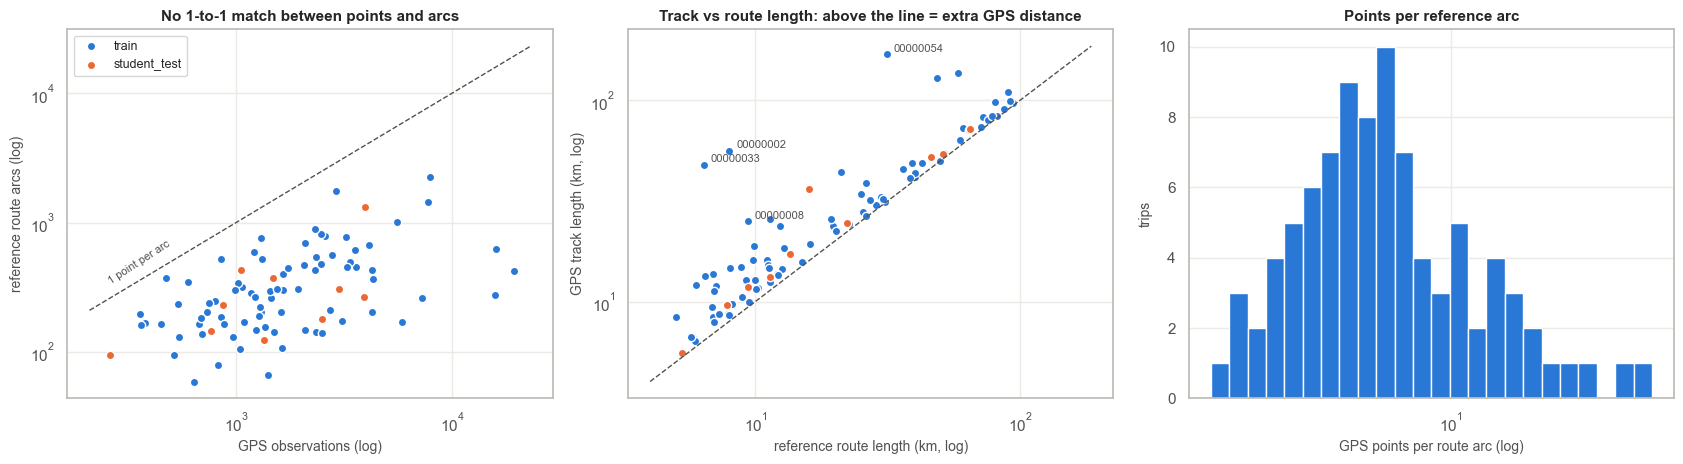

route continuity: 79 of 90 trips fully connected, min 98.1%
track/route length ratio: median 1.18


In [14]:
def route_length_km(trip):
    n = trip.nodes.to_numpy(); a = trip.arcs.to_numpy()[trip.route.arc_id.to_numpy()]
    return haversine_m(n[a[:, 0], 0], n[a[:, 0], 1], n[a[:, 1], 0], n[a[:, 1], 1]).sum() / 1000

inv["route_km"] = [route_length_km(load_trip(r.trip_id, r.partition, base_dir=ROOT)) for r in inv.itertuples()]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for p in PARTS:
    s = inv[inv.partition == p]
    ax[0].scatter(s.n_points, s.n_route_arcs, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
    ax[1].scatter(s.route_km, s.track_length_km, s=36, color=C[p], edgecolor="white", linewidth=1, label=p)
lim = [inv.n_points.min() * .8, inv.n_points.max() * 1.2]
ax[0].plot(lim, lim, color=INK, ls="--", lw=1); ax[0].text(lim[0] * 1.2, lim[0] * 1.6, "1 point per arc", fontsize=8, color=INK, rotation=33)
ax[0].set(xscale="log", yscale="log", xlabel="GPS observations (log)", ylabel="reference route arcs (log)",
          title="No 1-to-1 match between points and arcs")
ax[0].legend()
lim = [inv.route_km.min() * .8, inv[["route_km", "track_length_km"]].max().max() * 1.1]
ax[1].plot(lim, lim, color=INK, ls="--", lw=1)
for r in inv.assign(ratio=inv.track_length_km / inv.route_km).nlargest(4, "ratio").itertuples():
    ax[1].annotate(r.trip_id, (r.route_km, r.track_length_km), xytext=(5, 2), textcoords="offset points", fontsize=8, color=INK)
ax[1].set(xscale="log", yscale="log", xlabel="reference route length (km, log)", ylabel="GPS track length (km, log)",
          title="Track vs route length: above the line = extra GPS distance")
ax[2].hist(inv.points_per_route_arc, bins=np.logspace(np.log10(inv.points_per_route_arc.min()), np.log10(inv.points_per_route_arc.max()), 25),
           color=C["train"], edgecolor="white")
ax[2].set(xscale="log", xlabel="GPS points per route arc (log)", ylabel="trips", title="Points per reference arc")
save(fig, "10_route_structure.png")

print(f"route continuity: {(inv.route_continuity_pct == 100).sum()} of 90 trips fully connected, min {inv.route_continuity_pct.min():.1f}%")
print(f"track/route length ratio: median {(inv.track_length_km / inv.route_km).median():.2f}")

* **Cardinality.** Trips have between 1.3 and 57 GPS points per route arc (median about 6). Fast trips cross short arcs
  between two fixes, and slow ones sit on one arc for dozens of fixes. So per-point labels have to be **derived** by aligning points to the route in order
  (`src/labels.py`, monotone minimum-distance alignment). That alignment is itself an estimate, which is one more reason the labels are
  "reference", not ground truth.
* **Track vs route length.** Every trip sits on or just above the diagonal (median track/route ratio 1.18), which confirms that the route and the track describe the same
  journey. Trips well above it carry extra GPS distance the route does not explain: jitter (summing noisy 1 s steps inflates length), dwell (Section 4) or
  gap-induced jumps.
* **Continuity.** 79 of 90 routes are fully connected arc-to-arc. The rest have a handful of breaks (minimum 98.1%), so even the
  reference is not a perfect path through the graph and must not be treated as error-free.

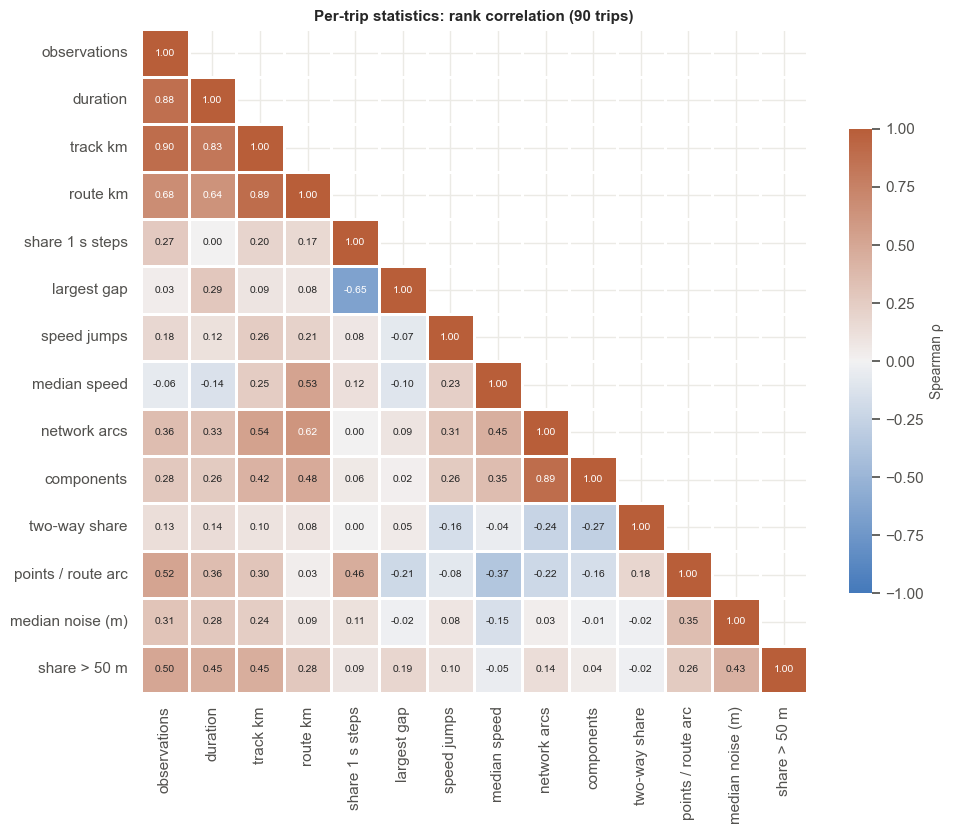

In [15]:
cols = {"n_points": "observations", "duration_s": "duration", "track_length_km": "track km", "route_km": "route km",
        "share_dt_1s": "share 1 s steps", "dt_max_s": "largest gap", "n_speed_jumps": "speed jumps",
        "speed_median_ms": "median speed", "n_arcs": "network arcs", "n_weak_components": "components",
        "two_way_arc_share": "two-way share", "points_per_route_arc": "points / route arc"}
m = inv.merge(per[["trip_id", "median", "far_share"]], on="trip_id")
m = m.rename(columns={"median": "median noise (m)", "far_share": "share > 50 m"})
corr = m[list(cols) + ["median noise (m)", "share > 50 m"]].rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(250, 25, s=75, l=50, center="light", as_cmap=True),
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=1, linecolor="white",
            cbar_kws={"label": "Spearman ρ", "shrink": .7}, ax=ax)
ax.set_title("Per-trip statistics: rank correlation (90 trips)")
save(fig, "11_trip_correlations.png")

Spearman (rank) correlation is used because every per-trip variable is heavy-tailed. The relationships worth noting:
network size is only **weakly related to trip length** (ρ ≈ 0.36), because networks are clipped generously around each trip. Speed is negatively
correlated with points per route arc (ρ ≈ −0.37): fast trips cross more arcs per second. The noise measures barely correlate with the sampling measures,
so **noise and gaps are separate problems** and each needs its own handling.

## 7. Candidate generation and feature sanity checks

For each GPS point the pipeline keeps up to **30 arcs within 250 m** (`data/feature_config.json`). Two questions:
does that set usually contain the true arc, and do the features separate it from the others?

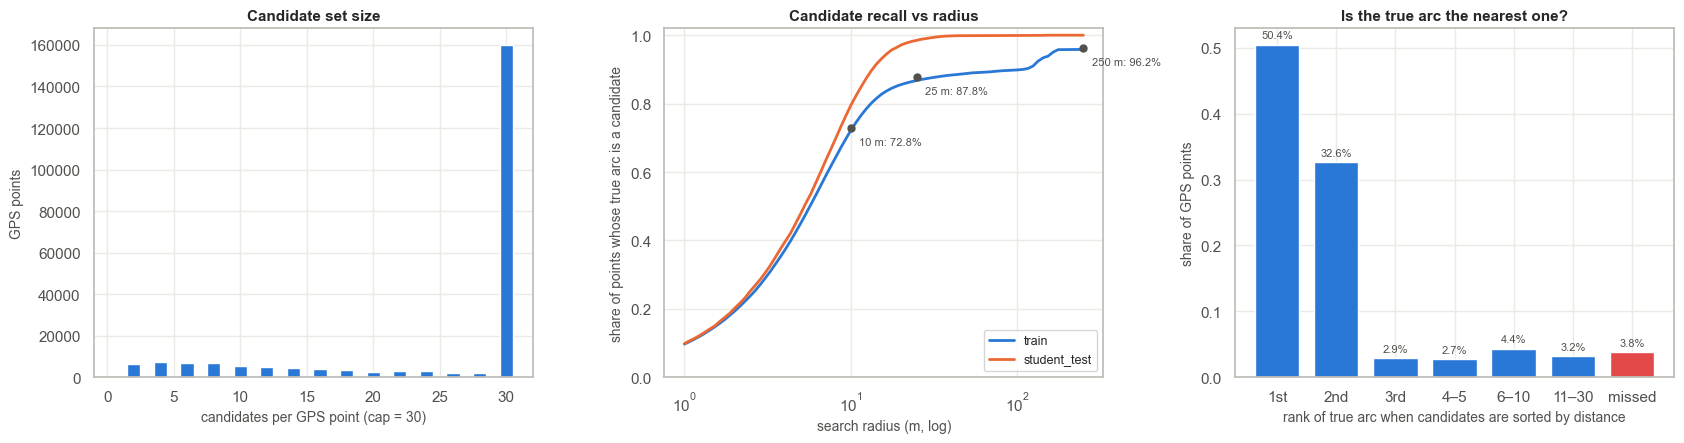

nearest-arc snapping would be correct for 50.4% of points; true arc missing from the candidate set: 3.82%


In [16]:
cand = pd.read_parquet(f"{ROOT}/data/candidates.parquet",
                       columns=["split", "trip_id", "obs_idx", "arc_id", "distance_m", "heading_cosine", "speed_mps", "label"])
cand = cand[cand.label >= 0]
cand["rank"] = cand.groupby(["trip_id", "obs_idx"]).distance_m.rank(method="first")
pos = cand[cand.label == 1].set_index(["trip_id", "obs_idx"])
ref = obs[obs.reference_available].set_index(["trip_id", "obs_idx"])
true_d = pos.distance_m.reindex(ref.index)      # NaN = true arc not among candidates
true_rank = pos["rank"].reindex(ref.index)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
nc = obs.n_candidates
ax[0].hist(nc, bins=np.arange(.5, 31.5), color=C["train"], edgecolor="white")
ax[0].set(xlabel="candidates per GPS point (cap = 30)", ylabel="GPS points", title="Candidate set size")

r = np.logspace(0, np.log10(250), 80)
for p in PARTS:
    td = true_d[ref.split == p]
    ax[1].plot(r, [(td <= x).sum() / len(td) for x in r], color=C[p], label=p)
for x in [10, 25, 250]:
    v = (true_d <= x).mean()
    ax[1].scatter([x], [v], color=INK, s=25, zorder=3); ax[1].annotate(f"{x} m: {v:.1%}", (x, v), xytext=(6, -12), textcoords="offset points", fontsize=8, color=INK)
ax[1].set(xscale="log", ylim=(0, 1.02), xlabel="search radius (m, log)", ylabel="share of points whose true arc is a candidate",
          title="Candidate recall vs radius")
ax[1].legend(loc="lower right")

rk = pd.cut(true_rank.fillna(99), [0, 1, 2, 3, 5, 10, 30, 100], labels=["1st", "2nd", "3rd", "4–5", "6–10", "11–30", "missed"])
share = rk.value_counts(normalize=True).reindex(rk.cat.categories)
bars = ax[2].bar(share.index.astype(str), share.values, color=[C["train"]] * 6 + [FLAG], width=.75)
for b, v in zip(bars, share.values):
    ax[2].text(b.get_x() + b.get_width() / 2, v + .01, f"{v:.1%}", ha="center", fontsize=8, color=INK)
ax[2].set(xlabel="rank of true arc when candidates are sorted by distance", ylabel="share of GPS points",
          title="Is the true arc the nearest one?")
save(fig, "12_candidate_recall.png")
print(f"nearest-arc snapping would be correct for {share.iloc[0]:.1%} of points; "
      f"true arc missing from the candidate set: {true_d.isna().mean():.2%}")

* The 250 m / 30 setting contains the true arc for about 96% of `train` points and almost 100% of `student_test` points. The `train`
  misses are concentrated in the two dwell trips from Section 4 (the curve's late jump at 100–200 m is them). Most points hit the 30-candidate cap,
  so in dense networks it is **k**, not the radius, that limits recall.
* **Nearest-arc snapping is right only about half the time** (rank 1 bar, 50%), and the true arc is 2nd for another third. The true arc is often the 2nd or 3rd nearest, typically
  the reverse-direction twin of a two-way road, or a short arc at a junction. A learned model plus the HMM therefore
  has real headroom over the naive baseline.

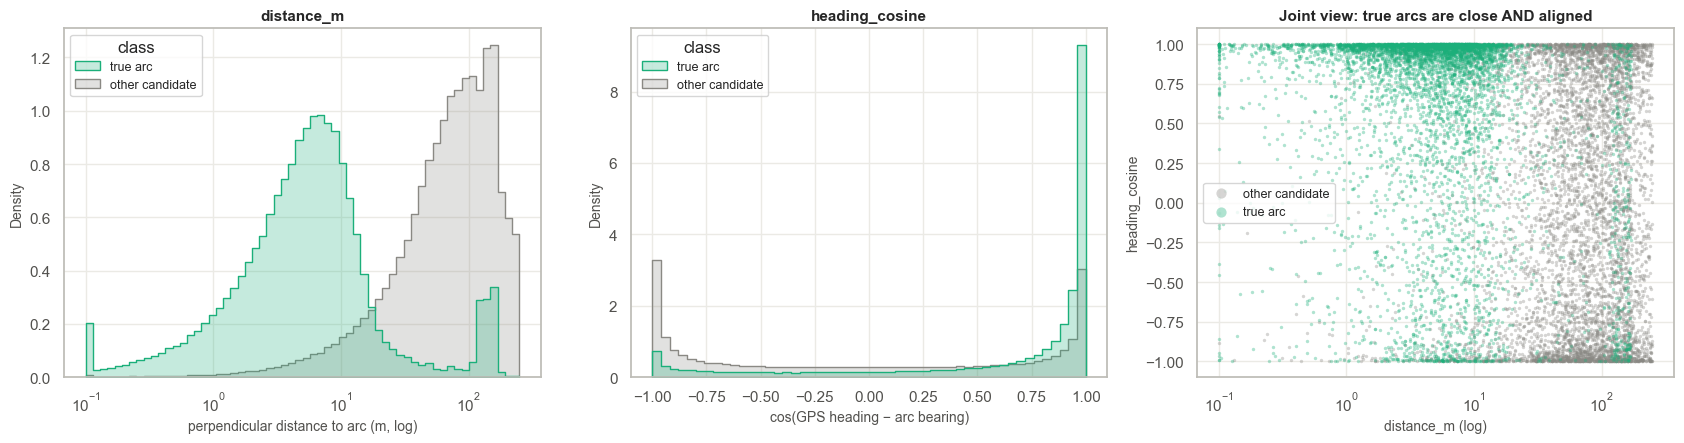

In [17]:
neg = cand[cand.label == 0].sample(min(400_000, (cand.label == 0).sum()), random_state=0)
both = pd.concat([cand[cand.label == 1], neg])
both["class"] = np.where(both.label == 1, "true arc", "other candidate")
pal = {"true arc": ROUTE, "other candidate": "#8a8984"}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(both, x=both.distance_m.clip(lower=.1), hue="class", log_scale=True, bins=60, stat="density",
             common_norm=False, element="step", palette=pal, ax=ax[0])
ax[0].set(xlabel="perpendicular distance to arc (m, log)", title="distance_m")
sns.histplot(both.dropna(subset=["heading_cosine"]), x="heading_cosine", hue="class", bins=50, stat="density",
             common_norm=False, element="step", palette=pal, ax=ax[1])
ax[1].set(xlabel="cos(GPS heading − arc bearing)", title="heading_cosine")

sub = both.dropna(subset=["heading_cosine"]).groupby("class", group_keys=False).apply(lambda s: s.sample(min(len(s), 6000), random_state=1))
for cls in ["other candidate", "true arc"]:
    s = sub[sub["class"] == cls]
    ax[2].scatter(s.distance_m.clip(lower=.1), s.heading_cosine, s=6, alpha=.35, color=pal[cls], label=cls, linewidths=0)
ax[2].set(xscale="log", xlabel="distance_m (log)", ylabel="heading_cosine", title="Joint view: true arcs are close AND aligned")
ax[2].legend(markerscale=3)
save(fig, "13_feature_separability.png")

The two strongest features separate the classes in complementary ways. **True arcs are close** (most within 10 m) and
**point the same way as the vehicle** (`heading_cosine` ≈ +1). Other candidates are spread over all distances, and many have
`heading_cosine` ≈ −1: those are the reverse twins of two-way roads, which distance alone cannot reject. The joint scatter shows
the true arcs concentrated in the top-left corner, so even a linear model should beat nearest-arc snapping, and tree
models can exploit the interaction.

## 8. Interactive Folium maps

Interactive maps (road network, reference route, raw GPS points, start/end markers, and layer toggles) are generated by
`maps/make_map.py` through `python -m src.eda`:

* `results/maps/eda_typical_train_00000095.html`: median-length training trip
* `results/maps/eda_largest_gap_train_00000090.html`: trip with the largest recording gap
* `results/maps/eda_student_test_student_test_00000000.html`: a student-test trip
* `maps/sample_trip_map.html`: sample map used in the demo

In [18]:
for f in ["results/maps/eda_typical_train_00000095.html", "results/maps/eda_largest_gap_train_00000090.html",
          "results/maps/eda_student_test_student_test_00000000.html", "maps/sample_trip_map.html"]:
    path = os.path.join(ROOT, f)
    print(f"{'OK     ' if os.path.exists(path) else 'MISSING'} {f}  ({os.path.getsize(path) / 1e6:.1f} MB)" if os.path.exists(path) else f"MISSING {f}")

OK      results/maps/eda_typical_train_00000095.html  (1.6 MB)
OK      results/maps/eda_largest_gap_train_00000090.html  (1.0 MB)
OK      results/maps/eda_student_test_student_test_00000000.html  (2.3 MB)
OK      maps/sample_trip_map.html  (5.8 MB)


## 9. Data-quality record, assumptions and decisions

| # | Finding | Evidence | Decision |
|---|---|---|---|
| 1 | Files are structurally clean: no NaNs, no invalid ids, no time reversals | Section 2 table | Parse with strict dtypes; keep integrity checks as guards for the evaluator data |
| 2 | Trips span 23 UTM zones in both hemispheres | Fig. 03 | Per-trip UTM projection; all distances in metres |
| 3 | About 3% of steps are not 1 s apart (up to 46% in single trips); gaps reach hours or days | Fig. 02 | Keep all points; `dt_s` feature; HMM transitions route through the graph and scale with `dt` |
| 4 | GPS jumps (> 70 m/s) exist | Fig. 05 | Keep; handled by emission probability, not deleted |
| 5 | GPS noise: median about 5–6 m, but bimodal with a 100–200 m hump | Fig. 06 | Fit emission noise on reliable points only |
| 6 | **Off-network dwell** in `00000054` and `00000033` causes most unreliable labels; a speed filter misses it | Figs. 07–08 | **Recommended:** drop `unreliable` rows from classifier training (not from evaluation) |
| 7 | Most roads are two-way pairs of directed arcs | Fig. 09 | `heading_cosine` is essential; nearest-arc snapping is right only about half the time |
| 8 | Networks are fragmented into many small components | Fig. 09 | HMM treats unreachable transitions as near-zero probability |
| 9 | Points ≠ route arcs; the reference itself has occasional breaks | Fig. 10 | Labels come from monotone alignment and are treated as *reference*, not ground truth |
| 10 | 250 m / 30 candidates contain the true arc for about 96% of train / about 100% of student_test points | Fig. 12 | Keep the radius; misses come mostly from the dwell trips |

**Leakage controls:** `.route` is read only when `load_reference=True` (training and label alignment); features never use it
(unit test `test_features_do_not_depend_on_route`); CV folds are grouped by `trip_id`; evaluator-test data is never loaded.